# HW2：以多元線性回歸 (Multiple Linear Regression) 預測人機互動中的信任分數

遵循 **CRISP-DM** 流程：Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment

- **資料集**：Human-AI Interaction（Kaggle）
- **來源連結**：https://www.kaggle.com/datasets/eshaalnmalik/human-ai-interaction/data
- **目標變數**：`latent_trust_score`（使用者對 AI 的潛在信任分數，連續值）
- **特徵數**：20 個（14 個數值型 + 6 個類別型）

## 1. Business Understanding

**情境**：AI 系統的價值取決於使用者是否「適度信任」它。信任過低，使用者會頻繁推翻（override）AI 的建議；信任過高，則可能忽略 AI 的錯誤。

**商業問題**：哪些因素（模型表現、使用者特性、任務環境）會影響使用者對 AI 的信任分數？能否用這些因素預測信任分數？

**分析目標**
1. 建立多元線性回歸模型預測 `latent_trust_score`。
2. 透過 Feature Selection 找出真正有影響力的因素，並解釋其方向與大小。
3. 以 MSE / RMSE / R² 與五大回歸假設檢驗評估模型。
4. 提供含**信賴區間 (Confidence Interval) 與預測區間 (Prediction Interval)** 的預測圖。
5. 以 Streamlit 部署成可互動的預測工具。

**成功標準**：測試集 R² 明顯優於僅用平均值預測（R² = 0），且模型符合主要回歸假設、結果可解釋。

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, ElasticNetCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFECV, RFE, SelectKBest, f_regression, SequentialFeatureSelector
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TARGET = "latent_trust_score"

## 2. Data Understanding

In [2]:
df = pd.read_csv("data/Human-AI_Interaction.csv")
print("資料形狀：", df.shape)
df.head()

資料形狀： (10100, 21)


,age,education_level,technical_experience,cognitive_load,prior_ai_exposure,model_accuracy,explainability_score,bias_level,decision_latency,error_rate,...,ui_complexity,feedback_quality,trust_history,override_frequency,task_risk,domain,time_pressure,cultural_factor,regulatory_strictness,latent_trust_score
0,23.0,Bachelor,10.0,0.165784,Low,0.751659,0.849591,0.997805,0.177149,0.240530,...,Medium,0.153828,0.098937,14.0,Medium,E-commerce,0.296228,Asian,1.0,53.997197
1,57.0,Bachelor,5.0,0.795383,High,0.942052,0.678777,0.608413,3.232353,0.069060,...,Medium,0.703003,0.945327,14.0,Low,Education,0.958935,Western,5.0,75.390600
2,22.0,Bachelor,1.0,0.985904,Medium,0.626350,0.741697,0.238885,4.591147,0.371519,...,Medium,0.949976,0.679748,15.0,Medium,Transportation,0.545855,African,3.0,76.728664
3,18.0,High School,9.0,0.643739,Low,0.517244,0.868427,0.866096,3.969884,0.486810,...,Medium,0.249026,0.293486,3.0,Low,Finance,0.897044,African,5.0,57.634055
4,32.0,Bachelor,9.0,0.639220,Medium,0.889796,0.627548,0.602626,3.695765,0.115761,...,Low,0.090495,0.148895,0.0,Low,E-commerce,0.353964,Asian,4.0,73.563222


In [3]:
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "缺失數": df.isna().sum(), "缺失率(%)": (df.isna().mean() * 100).round(2), "相異值數": df.nunique()})
info

,dtype,缺失數,缺失率(%),相異值數
age,float64,203,2.01,47
education_level,str,203,2.01,4
technical_experience,float64,201,1.99,21
cognitive_load,float64,203,2.01,9800
prior_ai_exposure,str,201,1.99,3
model_accuracy,float64,203,2.01,9800
explainability_score,float64,202,2.00,9800
bias_level,float64,201,1.99,9800
decision_latency,float64,202,2.00,9800
error_rate,float64,203,2.01,9800


In [4]:
print("重複列數：", df.duplicated().sum())
df.describe().T.round(3)

重複列數： 100


,count,mean,std,min,25%,50%,75%,max
age,9897.0,41.099,13.468,18.000,30.000,41.000,53.000,64.000
technical_experience,9899.0,10.048,6.039,0.000,5.000,10.000,15.000,20.000
cognitive_load,9897.0,0.495,0.286,0.000,0.246,0.496,0.737,1.000
model_accuracy,9897.0,0.749,0.144,0.500,0.624,0.751,0.874,1.000
explainability_score,9898.0,0.501,0.288,0.000,0.256,0.498,0.753,1.000
bias_level,9899.0,0.502,0.287,0.000,0.253,0.503,0.753,1.000
decision_latency,9898.0,2.565,1.411,0.101,1.331,2.596,3.786,4.999
error_rate,9897.0,0.250,0.146,-0.050,0.127,0.250,0.376,0.545
interaction_frequency,9898.0,24.997,14.115,1.000,13.000,25.000,37.000,49.000
feedback_quality,9900.0,0.499,0.289,0.000,0.246,0.498,0.751,1.000


In [5]:
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in df.select_dtypes("number").columns if c != TARGET]
print("數值特徵 (%d)：" % len(num_cols), num_cols)
print("類別特徵 (%d)：" % len(cat_cols), cat_cols)
for c in cat_cols:
    print(c, "->", sorted(df[c].dropna().unique()))

數值特徵 (14)： ['age', 'technical_experience', 'cognitive_load', 'model_accuracy', 'explainability_score', 'bias_level', 'decision_latency', 'error_rate', 'interaction_frequency', 'feedback_quality', 'trust_history', 'override_frequency', 'time_pressure', 'regulatory_strictness']
類別特徵 (6)： ['education_level', 'prior_ai_exposure', 'ui_complexity', 'task_risk', 'domain', 'cultural_factor']
education_level -> ['Bachelor', 'High School', 'Master', 'PhD']
prior_ai_exposure -> ['High', 'Low', 'Medium']
ui_complexity -> ['High', 'Low', 'Medium']
task_risk -> ['High', 'Low', 'Medium']
domain -> ['E-commerce', 'Education', 'Finance', 'Healthcare', 'Transportation']
cultural_factor -> ['African', 'Asian', 'Middle Eastern', 'Western']


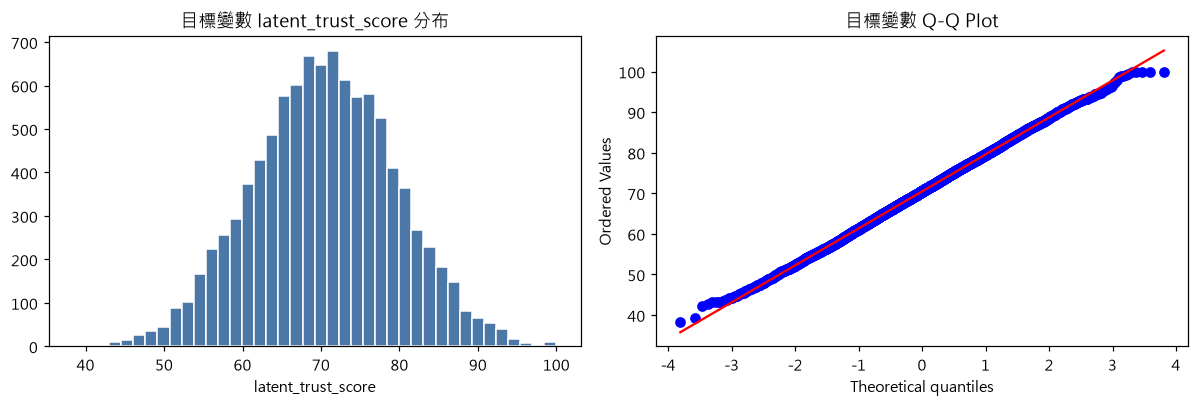

目標變數 = 100 的筆數（可能被截尾）： 4


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df[TARGET].dropna(), bins=40, color="#4C78A8", edgecolor="white")
axes[0].set_title("目標變數 latent_trust_score 分布")
axes[0].set_xlabel(TARGET)
stats.probplot(df[TARGET].dropna(), plot=axes[1])
axes[1].set_title("目標變數 Q-Q Plot")
plt.tight_layout(); plt.show()
print("目標變數 = 100 的筆數（可能被截尾）：", (df[TARGET] >= 100).sum())

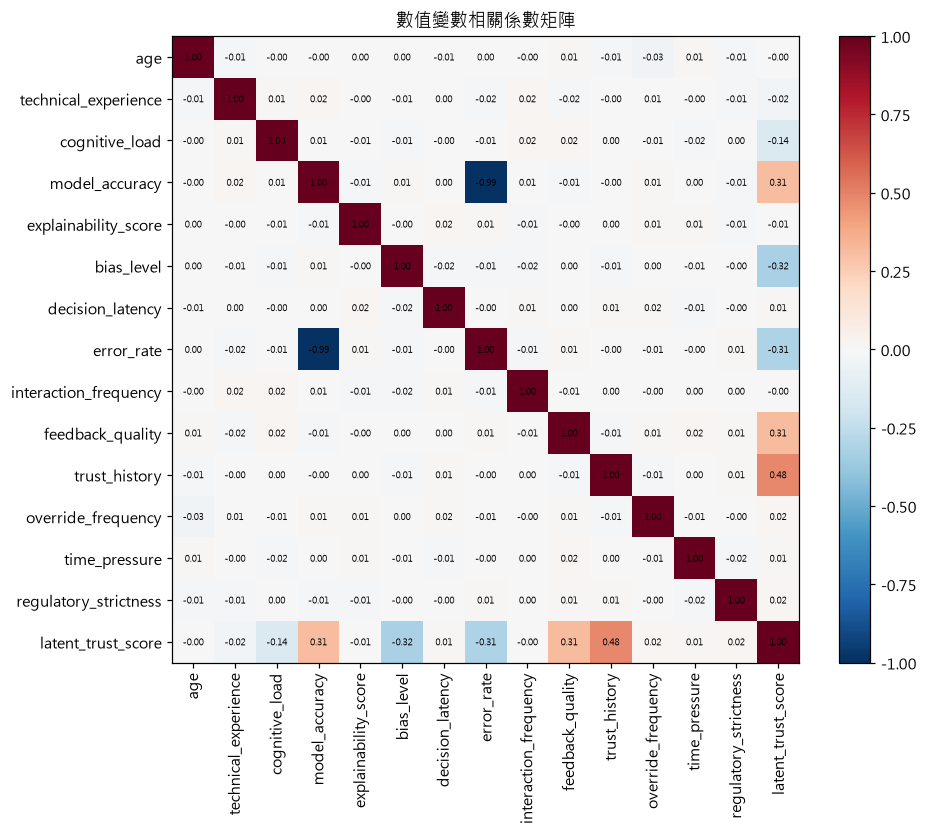

,與目標的相關係數
bias_level,-0.323
error_rate,-0.309
cognitive_load,-0.144
technical_experience,-0.024
explainability_score,-0.005
interaction_frequency,-0.004
age,-0.002
time_pressure,0.011
decision_latency,0.013
override_frequency,0.017


In [7]:
corr = df[num_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im); ax.set_title("數值變數相關係數矩陣"); plt.tight_layout(); plt.show()

corr[TARGET].drop(TARGET).sort_values().to_frame("與目標的相關係數").round(3)

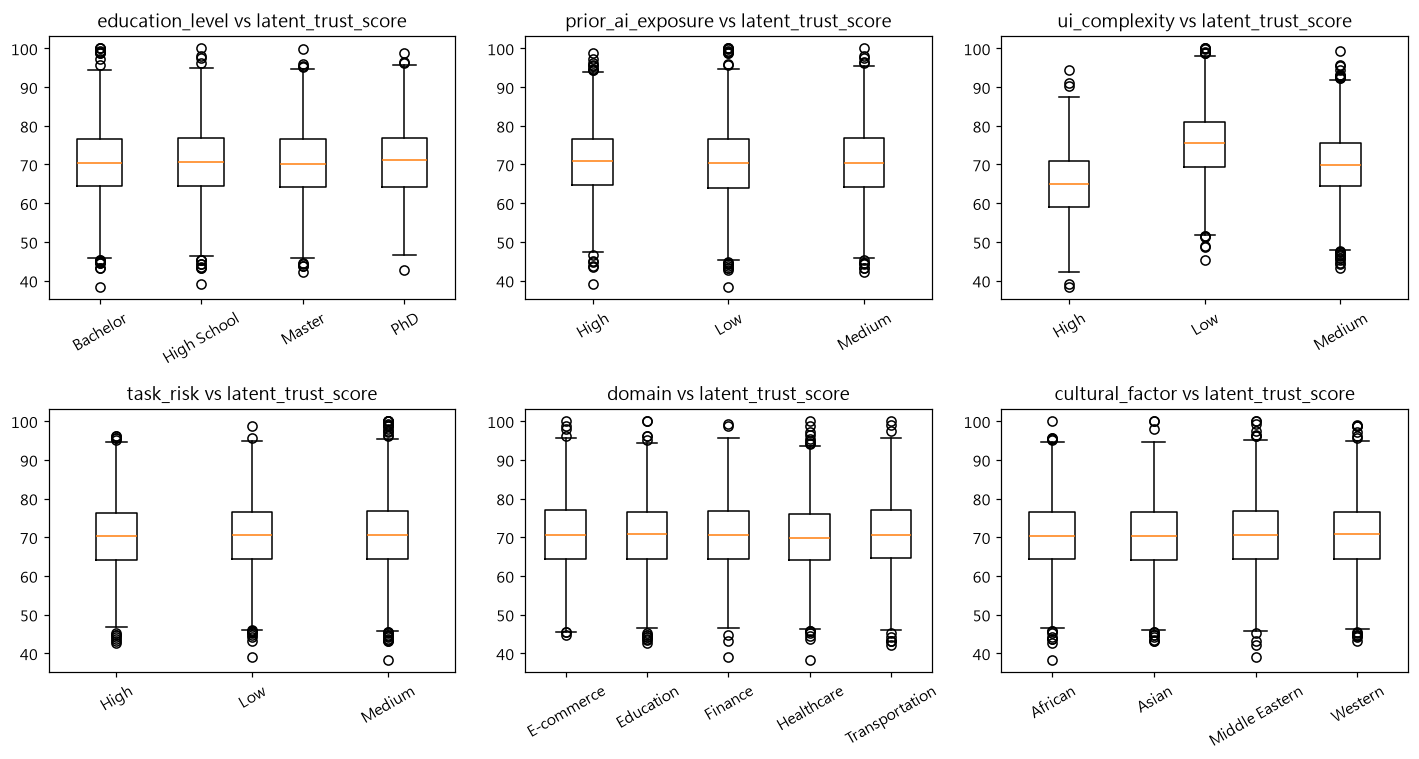

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), cat_cols):
    groups = [g[TARGET].dropna().values for _, g in df.groupby(c)]
    ax.boxplot(groups, tick_labels=[str(k) for k in sorted(df[c].dropna().unique())])
    ax.set_title(f"{c} vs {TARGET}"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**資料觀察**
- 共 10,100 筆、21 欄，每欄約有 2% 缺失值，且有重複列，需在 Data Preparation 處理。
- 與目標相關性最高的是 `trust_history`（正）、`bias_level`（負）、`error_rate`（負）、`feedback_quality`（正）、`model_accuracy`（正）、`cognitive_load`（負）。
- 除了 `model_accuracy` 與 `error_rate` 呈現極高的負相關（疑似重複資訊）外，其餘數值特徵彼此幾乎無相關；共線性將於 Modeling 階段以 VIF 驗證並處理。
- 數值特徵多為 0~1 的均勻分布，推測為模擬資料；目標變數上限為 100，可能有截尾現象。

## 3. Data Preparation

In [9]:
# 1) 移除重複列、目標變數缺失的列（目標不可插補）
n0 = len(df)
data = df.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
print(f"原始 {n0} 筆 -> 清理後 {len(data)} 筆")

# 2) 先切分訓練/測試集，再用「訓練集」的統計量插補，避免 data leakage
train_raw, test_raw = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)

num_median = train_raw[num_cols].median()
cat_mode = train_raw[cat_cols].mode().iloc[0]

def impute(d):
    d = d.copy()
    d[num_cols] = d[num_cols].fillna(num_median)
    d[cat_cols] = d[cat_cols].fillna(cat_mode)
    return d

train_raw, test_raw = impute(train_raw), impute(test_raw)
print("插補後剩餘缺失值：", train_raw.isna().sum().sum() + test_raw.isna().sum().sum())

原始 10100 筆 -> 清理後 9800 筆
插補後剩餘缺失值： 0


In [10]:
# 3) One-Hot Encoding（drop_first=True 避免 dummy variable trap）
def encode(d):
    X = pd.get_dummies(d.drop(columns=TARGET), columns=cat_cols, drop_first=True, dtype=float)
    return X, d[TARGET]

X_train, y_train = encode(train_raw)
X_test, y_test = encode(test_raw)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

print("訓練集：", X_train.shape, " 測試集：", X_test.shape)
print("編碼後特徵：", list(X_train.columns))

訓練集： (7840, 30)  測試集： (1960, 30)
編碼後特徵： ['age', 'technical_experience', 'cognitive_load', 'model_accuracy', 'explainability_score', 'bias_level', 'decision_latency', 'error_rate', 'interaction_frequency', 'feedback_quality', 'trust_history', 'override_frequency', 'time_pressure', 'regulatory_strictness', 'education_level_High School', 'education_level_Master', 'education_level_PhD', 'prior_ai_exposure_Low', 'prior_ai_exposure_Medium', 'ui_complexity_Low', 'ui_complexity_Medium', 'task_risk_Low', 'task_risk_Medium', 'domain_Education', 'domain_Finance', 'domain_Healthcare', 'domain_Transportation', 'cultural_factor_Asian', 'cultural_factor_Middle Eastern', 'cultural_factor_Western']


說明：OLS 對特徵尺度不敏感，且為了讓係數保持原始單位、便於解讀，**不做標準化**。

## 4. Modeling

### 4.1 基準模型：全特徵 Multiple Linear Regression

In [11]:
lr_full = LinearRegression().fit(X_train, y_train)
pred_full = lr_full.predict(X_test)
print(f"[全特徵] Test R² = {r2_score(y_test, pred_full):.4f}, RMSE = {np.sqrt(mean_squared_error(y_test, pred_full)):.4f}")

[全特徵] Test R² = 0.6943, RMSE = 4.9605


### 4.2 多重共線性檢查（VIF）

In [12]:
Xc = sm.add_constant(X_train)
vif = pd.DataFrame({"feature": X_train.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X_train.shape[1])]})
vif.sort_values("VIF", ascending=False).round(3).reset_index(drop=True)

,feature,VIF
0,error_rate,16.202
1,model_accuracy,16.199
2,prior_ai_exposure_Low,1.837
3,prior_ai_exposure_Medium,1.836
4,ui_complexity_Low,1.779
5,ui_complexity_Medium,1.779
6,task_risk_Low,1.726
7,task_risk_Medium,1.725
8,domain_Finance,1.661
9,domain_Transportation,1.612


**發現共線性問題**：`model_accuracy` 與 `error_rate` 的 VIF 皆超過 16（經驗法則：> 5 需關注、> 10 為嚴重），其餘特徵 VIF 都接近 1。兩者幾乎是同一資訊的正反面（準確度越高，錯誤率越低），同時放入模型會讓係數標準誤膨脹、係數不穩定。

**處理方式**：兩者與目標的相關係數幾乎相同（約 ±0.31），資訊高度重複，因此保留較直觀的 `model_accuracy`，移除 `error_rate`，並重新檢查 VIF。全特徵基準模型仍保留 30 個特徵，作為比較對象。

In [13]:
r = X_train[["model_accuracy", "error_rate"]].corr().iloc[0, 1]
print(f"corr(model_accuracy, error_rate) = {r:.3f}")

X_train_full, X_test_full = X_train.copy(), X_test.copy()   # 保留 30 特徵版本供比較
X_train = X_train.drop(columns="error_rate")
X_test = X_test.drop(columns="error_rate")

Xc = sm.add_constant(X_train)
vif_after = pd.DataFrame({"feature": X_train.columns,
                          "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X_train.shape[1])]})
print("移除 error_rate 後最大 VIF：", vif_after["VIF"].max().round(3))
vif_after.sort_values("VIF", ascending=False).head(5).round(3)

corr(model_accuracy, error_rate) = -0.969


移除 error_rate 後最大 VIF： 1.837


,feature,VIF
16,prior_ai_exposure_Low,1.837
17,prior_ai_exposure_Medium,1.836
19,ui_complexity_Medium,1.779
18,ui_complexity_Low,1.779
20,task_risk_Low,1.726


移除後所有特徵 VIF 皆 < 2，共線性問題解決。接著用七種不同原理的方法做 Feature Selection，交叉比對結果。

### 4.3 Feature Selection

In [14]:
# 方法 A：Backward Elimination（逐步剔除 p-value 最大且 > 0.05 的變數）
def backward_elimination(X, y, alpha=0.05):
    cols = list(X.columns)
    while True:
        res = sm.OLS(y, sm.add_constant(X[cols])).fit()
        pvals = res.pvalues.drop("const")
        worst = pvals.idxmax()
        if pvals[worst] <= alpha:
            return cols
        print(f"剔除 {worst:35s} p = {pvals[worst]:.4f}")
        cols.remove(worst)

sel_be = backward_elimination(X_train, y_train)
print("\n[A] Backward Elimination 保留 %d 個：" % len(sel_be), sel_be)

剔除 domain_Education                    p = 0.9897
剔除 age                                 p = 0.9542
剔除 time_pressure                       p = 0.8605
剔除 prior_ai_exposure_Medium            p = 0.8023
剔除 decision_latency                    p = 0.6905
剔除 task_risk_Medium                    p = 0.6725
剔除 education_level_Master              p = 0.5949
剔除 cultural_factor_Asian               p = 0.4981
剔除 domain_Healthcare                   p = 0.4804
剔除 domain_Finance                      p = 0.4920
剔除 explainability_score                p = 0.3959
剔除 education_level_High School         p = 0.3583
剔除 prior_ai_exposure_Low               p = 0.2986
剔除 cultural_factor_Western             p = 0.2485
剔除 cultural_factor_Middle Eastern      p = 0.2410
剔除 interaction_frequency               p = 0.1275
剔除 task_risk_Low                       p = 0.1039
剔除 technical_experience                p = 0.0959
剔除 domain_Transportation               p = 0.0866
剔除 education_level_PhD                 p = 0.0805


In [15]:
# 方法 B：LassoCV（L1 正則化，係數被壓為 0 者視為不重要；需先標準化）
mu, sd = X_train.mean(), X_train.std()
Xs_train = (X_train - mu) / sd                      # 標準化後的特徵，供 Lasso / RFE 使用
lasso = LassoCV(cv=5, random_state=RANDOM_STATE).fit(Xs_train, y_train)
sel_lasso = list(X_train.columns[lasso.coef_ != 0])
print(f"最佳 alpha = {lasso.alpha_:.5f}")
print("[B] LassoCV 保留 %d 個：" % len(sel_lasso), sel_lasso)

最佳 alpha = 0.01895
[B] LassoCV 保留 24 個： ['technical_experience', 'cognitive_load', 'model_accuracy', 'explainability_score', 'bias_level', 'decision_latency', 'interaction_frequency', 'feedback_quality', 'trust_history', 'override_frequency', 'regulatory_strictness', 'education_level_High School', 'education_level_Master', 'education_level_PhD', 'prior_ai_exposure_Low', 'ui_complexity_Low', 'ui_complexity_Medium', 'task_risk_Low', 'task_risk_Medium', 'domain_Education', 'domain_Finance', 'domain_Transportation', 'cultural_factor_Middle Eastern', 'cultural_factor_Western']


In [16]:
# 方法 C：RFECV（遞迴特徵消去 + 交叉驗證決定特徵數；用標準化特徵讓係數大小可比）
rfecv = RFECV(LinearRegression(), step=1, cv=5, scoring="neg_root_mean_squared_error").fit(Xs_train, y_train)
sel_rfe = list(X_train.columns[rfecv.support_])
print("[C] RFECV 保留 %d 個：" % len(sel_rfe), sel_rfe)

[C] RFECV 保留 9 個： ['cognitive_load', 'model_accuracy', 'bias_level', 'feedback_quality', 'trust_history', 'override_frequency', 'regulatory_strictness', 'ui_complexity_Low', 'ui_complexity_Medium']


In [17]:
K = len(sel_be)   # 讓固定特徵數的方法與 Backward Elimination 比較：同樣挑 K 個
print("固定特徵數 K =", K)

# 方法 D：SelectKBest（Filter：以單變量 F 統計量 f_regression 打分，取前 K 名）
skb = SelectKBest(f_regression, k=K).fit(X_train, y_train)
sel_kbest = list(X_train.columns[skb.get_support()])
print("[D] SelectKBest 保留 %d 個：" % len(sel_kbest), sel_kbest)

固定特徵數 K = 9
[D] SelectKBest 保留 9 個： ['technical_experience', 'cognitive_load', 'model_accuracy', 'bias_level', 'feedback_quality', 'trust_history', 'ui_complexity_Low', 'ui_complexity_Medium', 'task_risk_Medium']


In [18]:
# 方法 E：RFE（Wrapper：遞迴剔除標準化係數最小者，直到剩 K 個）
rfe = RFE(LinearRegression(), n_features_to_select=K).fit(Xs_train, y_train)
sel_rfe_k = list(X_train.columns[rfe.support_])
print("[E] RFE 保留 %d 個：" % len(sel_rfe_k), sel_rfe_k)

[E] RFE 保留 9 個： ['cognitive_load', 'model_accuracy', 'bias_level', 'feedback_quality', 'trust_history', 'override_frequency', 'regulatory_strictness', 'ui_complexity_Low', 'ui_complexity_Medium']


In [19]:
# 方法 F：Sequential Feature Selection（Wrapper：由 0 個特徵開始，逐步加入使 5-fold CV RMSE 下降最多者）
sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=K, direction="forward",
                                scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1).fit(X_train, y_train)
sel_sfs = list(X_train.columns[sfs.get_support()])
print("[F] SFS (forward) 保留 %d 個：" % len(sel_sfs), sel_sfs)

[F] SFS (forward) 保留 9 個： ['cognitive_load', 'model_accuracy', 'bias_level', 'feedback_quality', 'trust_history', 'override_frequency', 'regulatory_strictness', 'ui_complexity_Low', 'ui_complexity_Medium']


[G] Permutation Importance 保留 7 個： ['ui_complexity_Low', 'trust_history', 'model_accuracy', 'feedback_quality', 'bias_level', 'ui_complexity_Medium', 'cognitive_load']


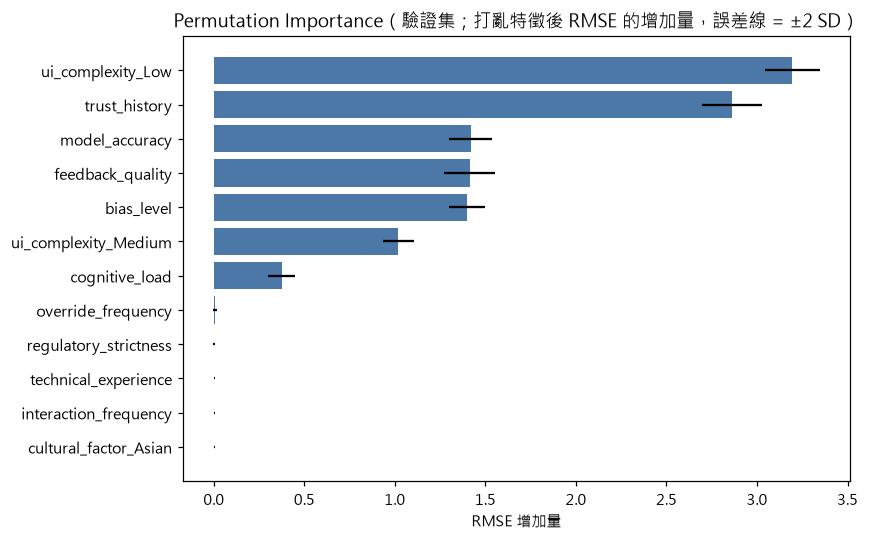

In [20]:
# 方法 G：Permutation Importance（以「預測表現下降多少」衡量重要性）
# 為避免使用測試集做選擇：把訓練集再切出 25% 作為驗證集；模型用其餘 75% 訓練，在驗證集上打亂各特徵 30 次
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
base_model = LinearRegression().fit(X_fit, y_fit)
pi_res = permutation_importance(base_model, X_val, y_val, scoring="neg_root_mean_squared_error",
                                n_repeats=30, random_state=RANDOM_STATE)
perm = pd.DataFrame({"importance_mean": pi_res.importances_mean, "importance_std": pi_res.importances_std},
                    index=X_train.columns).sort_values("importance_mean", ascending=False)

# 判準：打亂後 RMSE 的平均增幅 - 2 個標準差 > 0（即「顯著」造成預測變差）
sel_perm = list(perm.index[perm["importance_mean"] - 2 * perm["importance_std"] > 0])
print("[G] Permutation Importance 保留 %d 個：" % len(sel_perm), sel_perm)

top = perm.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["importance_mean"], xerr=2 * top["importance_std"], color="#4C78A8")
ax.set(title="Permutation Importance（驗證集；打亂特徵後 RMSE 的增加量，誤差線 = ±2 SD）", xlabel="RMSE 增加量")
plt.tight_layout(); plt.show()

In [21]:
methods = {
    "Backward(p<0.05)": sel_be,
    "LassoCV": sel_lasso,
    "RFECV": sel_rfe,
    "SelectKBest": sel_kbest,
    "RFE": sel_rfe_k,
    "SFS(forward)": sel_sfs,
    "Permutation": sel_perm,
}
summary = pd.DataFrame({name: [c in cols for c in X_train.columns] for name, cols in methods.items()}, index=X_train.columns)
summary["被選次數"] = summary.sum(axis=1)
summary.sort_values("被選次數", ascending=False)

,Backward(p<0.05),LassoCV,RFECV,SelectKBest,RFE,SFS(forward),Permutation,被選次數
cognitive_load,True,True,True,True,True,True,True,7
model_accuracy,True,True,True,True,True,True,True,7
trust_history,True,True,True,True,True,True,True,7
feedback_quality,True,True,True,True,True,True,True,7
bias_level,True,True,True,True,True,True,True,7
ui_complexity_Low,True,True,True,True,True,True,True,7
ui_complexity_Medium,True,True,True,True,True,True,True,7
regulatory_strictness,True,True,True,False,True,True,False,5
override_frequency,True,True,True,False,True,True,False,5
technical_experience,False,True,False,True,False,False,False,2


In [22]:
# 各方法選出的特徵子集，用 OLS 在「同一份」訓練 / 測試集上比較（選擇皆只用訓練集；測試集只做最後報告）
def adj_r2_(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

kf_sel = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, cols in methods.items():
    cv_rmse = -cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kf_sel, scoring="neg_root_mean_squared_error").mean()
    fit_ = LinearRegression().fit(X_train[cols], y_train)
    p = fit_.predict(X_test[cols])
    r2 = r2_score(y_test, p)
    rows.append({"方法": name, "特徵數": len(cols), "Train RMSE": np.sqrt(mean_squared_error(y_train, fit_.predict(X_train[cols]))),
                 "CV RMSE": cv_rmse, "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "Test R²": r2, "Test Adj R²": adj_r2_(r2, len(y_test), len(cols))})
selection_rmse = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
selection_rmse.round(4)

,方法,特徵數,Train RMSE,CV RMSE,Test RMSE,Test R²,Test Adj R²
0,Backward(p<0.05),9,5.0910,5.0977,4.9608,0.6943,0.6928
1,RFECV,9,5.0910,5.0977,4.9608,0.6943,0.6928
2,SFS(forward),9,5.0910,5.0977,4.9608,0.6943,0.6928
3,RFE,9,5.0910,5.0977,4.9608,0.6943,0.6928
4,SelectKBest,9,5.0943,5.1016,4.9574,0.6947,0.6932
5,LassoCV,24,5.0844,5.1017,4.9630,0.6940,0.6902
6,Permutation,7,5.0958,5.1021,4.9584,0.6945,0.6934


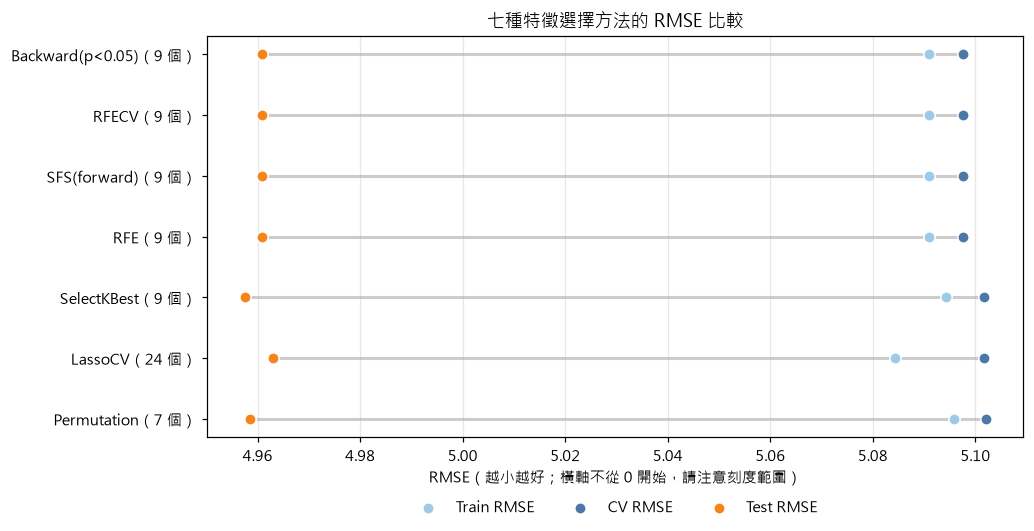

七組 CV RMSE 最大差距：0.0044（約 0.09%）


In [23]:
RMSE_COLORS = {"Train RMSE": "#9ecae9", "CV RMSE": "#4C78A8", "Test RMSE": "#F58518"}

def rmse_grouped_barh(df, labels, title):
    """Train / CV / Test 三種 RMSE 的點圖（Dot plot）：點的位置表示 RMSE，橫軸不從 0 開始，故不以長度比較大小。"""
    cols = list(RMSE_COLORS)
    n = len(df)
    y = np.arange(n)
    fig, ax = plt.subplots(figsize=(9.5, 0.45 * n + 1.8))
    ax.hlines(y, df[cols].min(axis=1), df[cols].max(axis=1), color="#cccccc", lw=2, zorder=1)
    for c in cols:
        ax.scatter(df[c], y, s=55, color=RMSE_COLORS[c], label=c, zorder=2, edgecolor="white")
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
    ax.set(title=title, xlabel="RMSE（越小越好；橫軸不從 0 開始，請注意刻度範圍）")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    plt.tight_layout(); plt.show()

rmse_grouped_barh(selection_rmse, selection_rmse["方法"] + "（" + selection_rmse["特徵數"].astype(str) + " 個）", "七種特徵選擇方法的 RMSE 比較")
print(f"七組 CV RMSE 最大差距：{selection_rmse['CV RMSE'].max() - selection_rmse['CV RMSE'].min():.4f}"
      f"（約 {(selection_rmse['CV RMSE'].max() / selection_rmse['CV RMSE'].min() - 1):.2%}）")

**RMSE 比較解讀（特徵選擇）**
- 七種方法的 Train RMSE 約 5.08 ~ 5.10、CV RMSE 約 5.098 ~ 5.102、Test RMSE 約 4.957 ~ 4.963，**差距都在 0.1% 以內**，圖上的點幾乎重疊，方法之間沒有實質的預測力差異。
- **Train 與 CV RMSE 非常接近**（相差不到 0.01），表示模型沒有過度擬合。
- Test RMSE（約 4.96）略低於 Train / CV（約 5.09），是這次 80/20 切分的測試集剛好較容易預測所致，並非模型有「額外」表現，因此選擇模型時應以 CV RMSE 為準。
- 24 個特徵的 LassoCV 的 Train RMSE 最低（5.084），但 CV RMSE 並沒有比較好，代表多出來的特徵只是在訓練集上多擬合了一點點。

**七種方法的比較**

| 類型 | 方法 | 準則 | 保留數 |
|---|---|---|---|
| 統計檢定 | A. Backward Elimination | p-value < 0.05 | 9 |
| 嵌入式 (Embedded) | B. LassoCV | L1 收縮到 0 | 24 |
| 包裝式 (Wrapper) | C. RFECV | 遞迴剔除 + CV 決定個數 | 9 |
| 過濾式 (Filter) | D. SelectKBest | 單變量 F 統計量，取前 K 名 | 9（指定） |
| 包裝式 | E. RFE | 遞迴剔除標準化係數最小者 | 9（指定） |
| 包裝式 | F. Sequential Feature Selection | 前向逐步加入，使 CV RMSE 最小 | 9（指定） |
| 模型無關 | G. Permutation Importance | 打亂特徵後驗證集 RMSE 顯著上升 | 7 |

**觀察**
- **核心特徵高度一致**：`trust_history`、`model_accuracy`、`bias_level`、`feedback_quality`、`cognitive_load`、`ui_complexity`（Low / Medium，同一個原始特徵）被**全部七種方法**同時選中。
- **`override_frequency` 與 `regulatory_strictness`**：被 5 種方法選中，但 SelectKBest 與 Permutation Importance 都沒選。這與前面的結果一致——它們在統計上顯著（p < 0.05），但係數僅 0.03 與 0.09，對預測的實際貢獻極小。
- **Backward、RFECV、RFE、SFS 四種方法選出完全相同的 9 個特徵**。這是因為各特徵的訊號強弱差距很大（核心特徵影響明顯、其餘近乎為零），不同演算法才會收斂到同一組。
- **SelectKBest（Filter）** 是唯一不同的：它只看單變量關係，沒有考慮特徵之間的聯合效應，因此挑進了 `technical_experience`、`task_risk_Medium` 這類邊際相關的特徵，卻漏掉 `override_frequency` 與 `regulatory_strictness`。
- **LassoCV** 以預測誤差為準則，會保留許多影響極小的變數（24 個）；這些變數沒有帶來額外預測力。

**預測表現比較**（下方最後一張表）：七組特徵子集在 OLS 下的 CV RMSE 介於 5.098 ~ 5.102，差距不到 0.1%，在實務上沒有差別；7 個特徵（Permutation）與 24 個特徵（Lasso）的預測力幾乎一樣。

**最終決定**：採用 **Backward Elimination 的 9 個特徵**。理由：(1) 與 RFECV / RFE / SFS 三種方法結果相同，結論穩健；(2) 它以統計顯著性為準則，能直接對應 OLS 的係數檢定與區間推論；(3) 預測表現與其他方法無實質差異。若想要更精簡的模型，7 個特徵的 Permutation 版本也是合理選擇。

### 4.4 最終模型（statsmodels OLS）

In [24]:
selected = sel_be
ols = sm.OLS(y_train, sm.add_constant(X_train[selected])).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:     latent_trust_score   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.690
Method:                 Least Squares   F-statistic:                     1937.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:26:20   Log-Likelihood:                -23884.
No. Observations:                7840   AIC:                         4.779e+04
Df Residuals:                    7830   BIC:                         4.786e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    44.61

In [25]:
coef = pd.DataFrame({"係數": ols.params, "標準誤": ols.bse, "p-value": ols.pvalues}).join(ols.conf_int().rename(columns={0: "95% CI 下界", 1: "95% CI 上界"}))
coef.drop("const").sort_values("係數").round(4)

,係數,標準誤,p-value,95% CI 下界,95% CI 上界
bias_level,-10.1151,0.2034,0.0000,-10.5138,-9.7165
cognitive_load,-5.0941,0.2033,0.0000,-5.4926,-4.6955
override_frequency,0.0308,0.0100,0.0021,0.0112,0.0505
regulatory_strictness,0.0941,0.0409,0.0214,0.0140,0.1743
ui_complexity_Medium,4.8644,0.1533,0.0000,4.5639,5.1648
ui_complexity_Low,9.9430,0.1684,0.0000,9.6130,10.2731
feedback_quality,10.0596,0.2009,0.0000,9.6659,10.4534
trust_history,15.0204,0.2015,0.0000,14.6254,15.4153
model_accuracy,20.0023,0.4030,0.0000,19.2124,20.7922


## 5. Evaluation

### 5.1 模型效能比較（全特徵 vs. 特徵選擇後）

In [26]:
def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate(model, cols, name, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr
    Xte = X_test if Xte is None else Xte
    kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
    cv_rmse = -cross_val_score(LinearRegression(), Xtr[cols], y_train, cv=kf, scoring="neg_root_mean_squared_error")
    rows = {}
    for split, X, y in [("Train", Xtr[cols], y_train), ("Test", Xte[cols], y_test)]:
        p = model.predict(X)
        mse = mean_squared_error(y, p)
        r2 = r2_score(y, p)
        rows[split] = {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, p), "R²": r2, "Adj R²": adj_r2(r2, len(y), len(cols))}
    out = pd.DataFrame(rows).T
    out["特徵數"] = len(cols)
    out["5-fold CV RMSE"] = [cv_rmse.mean(), np.nan]
    out.index = [f"{name} - {i}" for i in out.index]
    return out

lr_sel = LinearRegression().fit(X_train[selected], y_train)
results = pd.concat([evaluate(lr_full, list(X_train_full.columns), "全特徵", X_train_full, X_test_full), evaluate(lr_sel, selected, "特徵選擇後")])
results.round(4)

,MSE,RMSE,MAE,R²,Adj R²,特徵數,5-fold CV RMSE
全特徵 - Train,25.7265,5.0721,4.0343,0.6923,0.6911,30,5.0956
全特徵 - Test,24.6066,4.9605,3.9155,0.6943,0.6895,30,NaN
特徵選擇後 - Train,25.9179,5.0910,4.0451,0.6900,0.6897,9,5.0977
特徵選擇後 - Test,24.6091,4.9608,3.9249,0.6943,0.6928,9,NaN


### 5.1.1 模型比較：OLS vs. Ridge vs. Lasso vs. ElasticNet

為了檢驗「加入正則化 (Regularization) 是否能進一步改善預測」，將 OLS 與三種正則化回歸，在三組特徵集上比較：

- **30 特徵**：全部特徵（含高度共線的 `model_accuracy` 與 `error_rate`）
- **29 特徵**：移除 `error_rate`
- **9 特徵**：Backward Elimination 選出的最終特徵

正則化模型的超參數（alpha、l1_ratio）皆以訓練集 5-fold CV 選定，並先做標準化（Ridge / Lasso 對特徵尺度敏感）。「CV RMSE」為把整個調參流程放進 5-fold CV 的結果（nested CV，不受測試集影響），模型選擇應以它為準，Test 指標僅作最後確認。

In [27]:
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-3, 3, 60)

feature_sets = {
    "30 特徵（全特徵）": (X_train_full, X_test_full),
    "29 特徵（移除 error_rate）": (X_train, X_test),
    "9 特徵（Backward）": (X_train[selected], X_test[selected]),
}
model_makers = {
    "OLS": lambda: LinearRegression(),
    "Ridge": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=kf)),
    "Lasso": lambda: make_pipeline(StandardScaler(), LassoCV(cv=kf, random_state=RANDOM_STATE)),
    "ElasticNet": lambda: make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9, 0.99], cv=kf, random_state=RANDOM_STATE)),
}

def hyper(model):
    if not hasattr(model, "steps"):
        return "-"
    est = model.steps[-1][1]
    if hasattr(est, "l1_ratio_"):
        return f"alpha={est.alpha_:.4f}, l1_ratio={est.l1_ratio_}"
    return f"alpha={est.alpha_:.4f}"

rows = []
for fs_name, (Xtr, Xte) in feature_sets.items():
    for m_name, make in model_makers.items():
        cv_rmse = -cross_val_score(make(), Xtr, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()
        mdl = make().fit(Xtr, y_train)
        p = mdl.predict(Xte)
        r2 = r2_score(y_test, p)
        rows.append({"特徵集": fs_name, "模型": m_name, "超參數": hyper(mdl),
                     "Train RMSE": np.sqrt(mean_squared_error(y_train, mdl.predict(Xtr))), "CV RMSE": cv_rmse, "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
                     "Test MAE": mean_absolute_error(y_test, p), "Test R²": r2,
                     "Test Adj R²": adj_r2(r2, len(y_test), Xtr.shape[1])})

comparison = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
comparison.round(4)

,特徵集,模型,超參數,Train RMSE,CV RMSE,Test RMSE,Test MAE,Test R²,Test Adj R²
0,30 特徵（全特徵）,Lasso,alpha=0.0288,5.0746,5.0941,4.9546,3.9125,0.6950,0.6903
1,30 特徵（全特徵）,ElasticNet,"alpha=0.0291, l1_ratio=0.99",5.0746,5.0943,4.9546,3.9126,0.6950,0.6903
2,30 特徵（全特徵）,Ridge,alpha=23.5983,5.0722,5.0955,4.9601,3.9153,0.6943,0.6896
3,30 特徵（全特徵）,OLS,-,5.0721,5.0956,4.9605,3.9155,0.6943,0.6895
4,9 特徵（Backward）,Ridge,alpha=0.4406,5.0910,5.0977,4.9607,3.9249,0.6943,0.6928
5,9 特徵（Backward）,OLS,-,5.0910,5.0977,4.9608,3.9249,0.6943,0.6928
6,9 特徵（Backward）,Lasso,alpha=0.0044,5.0910,5.0977,4.9604,3.9246,0.6943,0.6929
7,9 特徵（Backward）,ElasticNet,"alpha=0.0044, l1_ratio=0.99",5.0910,5.0977,4.9604,3.9246,0.6943,0.6929
8,29 特徵（移除 error_rate）,ElasticNet,"alpha=0.0291, l1_ratio=0.99",5.0866,5.1042,4.9578,3.9212,0.6946,0.6900
9,29 特徵（移除 error_rate）,Lasso,alpha=0.0309,5.0868,5.1042,4.9577,3.9212,0.6946,0.6900


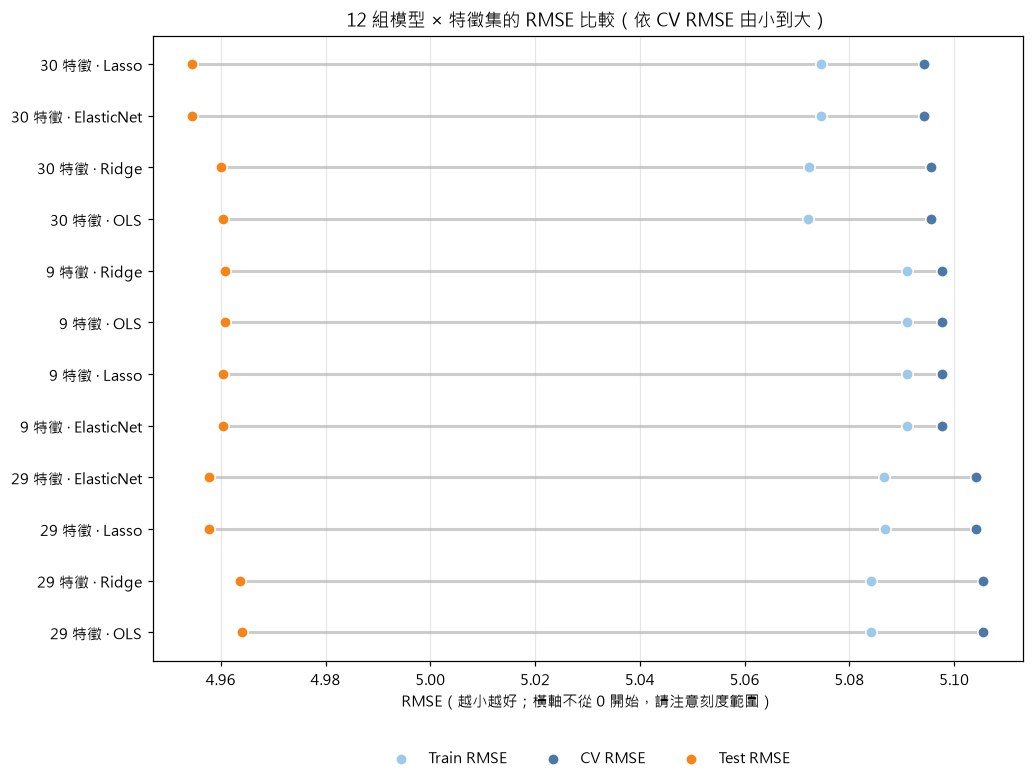

12 組 CV RMSE 的最大差距：0.0114（約 0.22%）


In [28]:
lab = comparison["特徵集"].str.split("（").str[0] + " · " + comparison["模型"]
rmse_grouped_barh(comparison, lab, "12 組模型 × 特徵集的 RMSE 比較（依 CV RMSE 由小到大）")
lo, hi = comparison["CV RMSE"].min(), comparison["CV RMSE"].max()
print(f"12 組 CV RMSE 的最大差距：{hi - lo:.4f}（約 {(hi - lo) / lo:.2%}）")

**模型比較解讀**
- **三種 RMSE 一致**：Train（5.07 ~ 5.09）與 CV（5.09 ~ 5.11）幾乎相同，Test（4.95 ~ 4.96）略低，沒有過度擬合的跡象；圖中每一列的三個點都擠在很窄的範圍內。
- **正則化沒有實質幫助**：12 組組合的 CV RMSE 僅介於 5.094 ~ 5.106，最大差距約 0.22%；Test RMSE 皆約 4.95 ~ 4.96。在同一特徵集內，OLS、Ridge、Lasso、ElasticNet 幾乎相同（9 特徵時四者連小數第四位都一致）。
- 原因：樣本數（約 7,800 筆）遠大於特徵數，且共線性已處理，OLS 本身不會過度擬合，Ridge / Lasso 的收縮 (shrinkage) 沒有發揮空間。Lasso 在 9 特徵上選出的 alpha 極小（0.0044），等同於不收縮。
- **特徵數也差不多**：9 特徵與 30 特徵的 CV RMSE 相差僅 0.002，但 9 特徵模型更精簡、可解釋，且 Adjusted R² 更高（0.693 vs 0.690）。
- **關於移除 `error_rate`**：29 特徵的 CV RMSE（5.106）略高於 30 特徵（5.096），差距約 0.2%，表示 `error_rate` 帶有極少量 `model_accuracy` 以外的資訊。但為了避免 VIF > 16 造成的係數不穩定與假設檢驗失敗，並且最終 9 特徵模型的 CV RMSE（5.098）與 30 特徵幾乎相同，這個取捨是值得的。
- **結論**：以「簡單、可解釋、假設可驗證」為原則，仍採用 **OLS + 9 特徵** 作為最終模型；因為 OLS 才能直接給出可靠的信賴區間與預測區間。

### 5.2 五大回歸假設檢驗

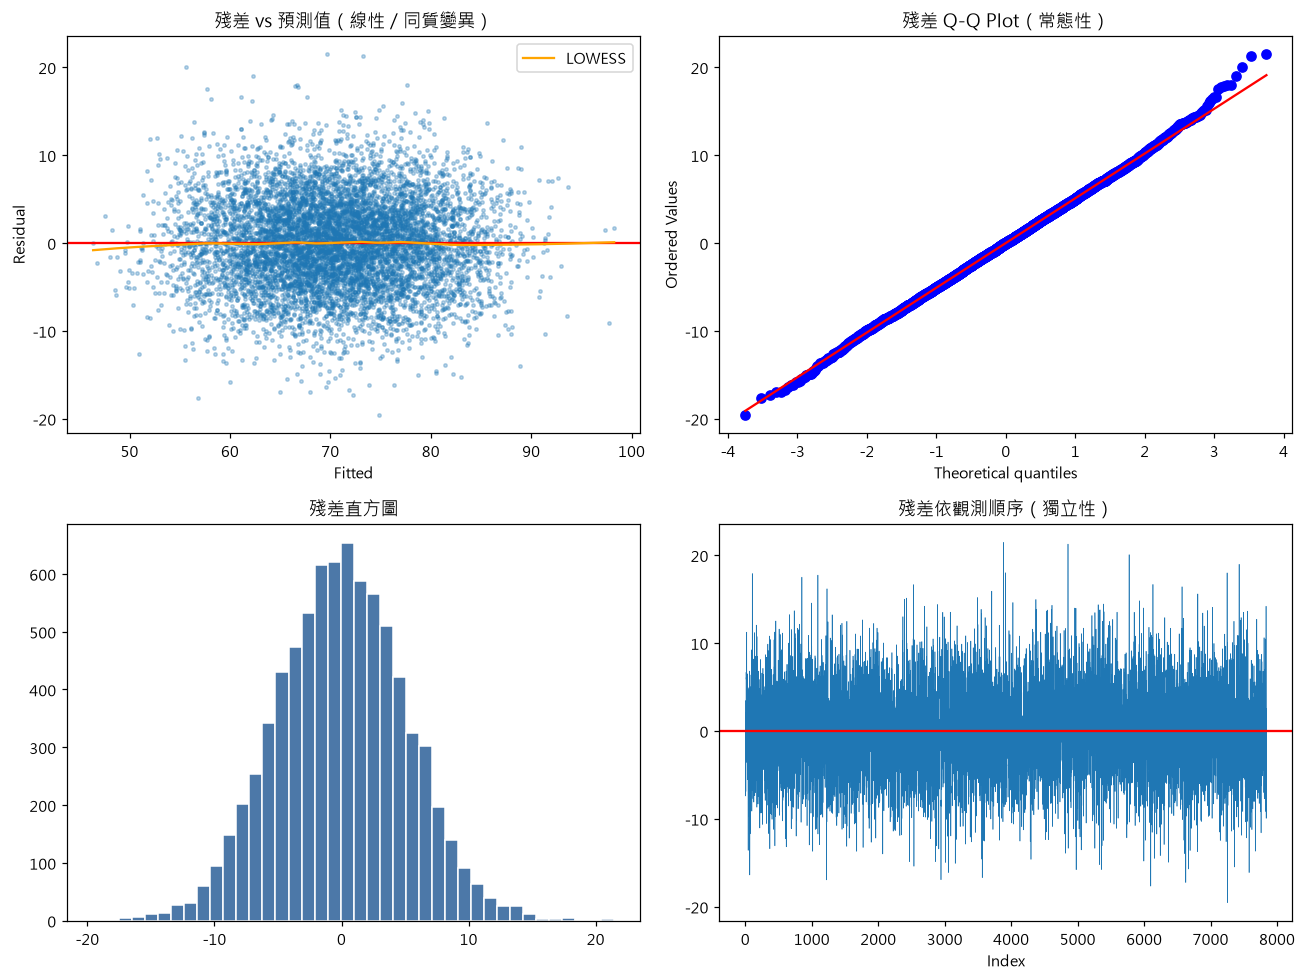

In [29]:
resid = ols.resid
fitted = ols.fittedvalues
Xs = sm.add_constant(X_train[selected])

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# (1) 線性 & (3) 同質變異：殘差 vs 預測值
axes[0, 0].scatter(fitted, resid, s=5, alpha=0.3)
axes[0, 0].axhline(0, color="red")
lw = sm.nonparametric.lowess(resid, fitted, frac=0.3)
axes[0, 0].plot(lw[:, 0], lw[:, 1], color="orange", label="LOWESS")
axes[0, 0].set(title="殘差 vs 預測值（線性 / 同質變異）", xlabel="Fitted", ylabel="Residual"); axes[0, 0].legend()
# (4) 常態性
stats.probplot(resid, plot=axes[0, 1]); axes[0, 1].set_title("殘差 Q-Q Plot（常態性）")
axes[1, 0].hist(resid, bins=40, color="#4C78A8", edgecolor="white"); axes[1, 0].set_title("殘差直方圖")
# (2) 獨立性：殘差依觀測順序
axes[1, 1].plot(resid.values, lw=0.4); axes[1, 1].axhline(0, color="red")
axes[1, 1].set(title="殘差依觀測順序（獨立性）", xlabel="Index")
plt.tight_layout(); plt.show()

In [30]:
alpha = 0.05
reset_p = linear_reset(ols, power=2, use_f=True).pvalue
dw = durbin_watson(resid)
bp_p = het_breuschpagan(resid, Xs)[1]
sw_stat, sw_p = stats.shapiro(resid.sample(min(5000, len(resid)), random_state=RANDOM_STATE))
jb_stat, jb_p = stats.jarque_bera(resid)
vif_sel = max(variance_inflation_factor(Xs.values, i + 1) for i in range(len(selected)))

checks = pd.DataFrame([
    ["1. 線性 (Linearity)", "Ramsey RESET", f"p = {reset_p:.4f}", "p > 0.05 為通過", reset_p > alpha],
    ["2. 獨立性 (Independence)", "Durbin-Watson", f"DW = {dw:.3f}", "約 1.5~2.5 為通過", 1.5 <= dw <= 2.5],
    ["3. 同質變異 (Homoscedasticity)", "Breusch-Pagan", f"p = {bp_p:.4f}", "p > 0.05 為通過", bp_p > alpha],
    ["4. 殘差常態 (Normality)", "Shapiro-Wilk", f"p = {sw_p:.4f}", "p > 0.05 為通過", sw_p > alpha],
    ["4. 殘差常態 (Normality)", "Jarque-Bera", f"p = {jb_p:.4f}", "p > 0.05 為通過", jb_p > alpha],
    ["5. 無共線性 (No multicollinearity)", "最大 VIF", f"{vif_sel:.3f}", "< 5 為通過", vif_sel < 5],
], columns=["假設", "檢定", "結果", "判準", "是否通過"])
checks

,假設,檢定,結果,判準,是否通過
0,1. 線性 (Linearity),Ramsey RESET,p = 0.2166,p > 0.05 為通過,True
1,2. 獨立性 (Independence),Durbin-Watson,DW = 2.017,約 1.5~2.5 為通過,True
2,3. 同質變異 (Homoscedasticity),Breusch-Pagan,p = 0.6886,p > 0.05 為通過,True
3,4. 殘差常態 (Normality),Shapiro-Wilk,p = 0.0689,p > 0.05 為通過,True
4,4. 殘差常態 (Normality),Jarque-Bera,p = 0.0089,p > 0.05 為通過,False
5,5. 無共線性 (No multicollinearity),最大 VIF,1.774,< 5 為通過,True


In [31]:
print("殘差偏態 skew = %.3f, 峰度 excess kurtosis = %.3f" % (stats.skew(resid), stats.kurtosis(resid)))

殘差偏態 skew = 0.040, 峰度 excess kurtosis = 0.150


**假設檢驗解讀**
1. **線性**：Ramsey RESET p = 0.217，殘差 vs 預測值圖的 LOWESS 曲線貼近 0，沒有明顯曲線趨勢 → 通過。
2. **獨立性**：Durbin-Watson = 2.02（接近 2 表示無自相關）→ 通過。此資料並非時間序列，殘差順序圖也無趨勢。
3. **同質變異**：Breusch-Pagan p = 0.689，殘差散布寬度不隨預測值改變 → 通過。
4. **殘差常態**：Shapiro-Wilk p = 0.069 通過；但 Jarque-Bera p = 0.009 **未通過**。不過殘差偏態僅 0.04、超額峰度僅 0.15，Q-Q Plot 幾乎貼合直線；在樣本數近 8,000 筆時，常態性檢定對極小偏離也會顯著，且大樣本下係數推論仍穩健，因此判斷偏離程度在實務上可接受。
5. **無共線性**：移除 `error_rate` 後最大 VIF = 1.77 < 5 → 通過（移除前 `model_accuracy` 與 `error_rate` 的 VIF 皆 > 16）。

綜合：五大假設中四項通過，常態性僅有輕微且實務上可忽略的偏離，OLS 的係數、信賴區間與預測區間可被信任。

### 5.3 預測圖：信賴區間 (CI) 與預測區間 (PI)

- **95% 信賴區間 (Confidence Interval)**：「平均反應」的不確定性，即在相同特徵下，真實平均信任分數會落在哪個範圍。
- **95% 預測區間 (Prediction Interval)**：「單一新觀測值」的不確定性，額外包含殘差變異，因此比 CI 寬很多。

測試集實際值落在 95% 預測區間內的比例：95.5%（理想約 95%）


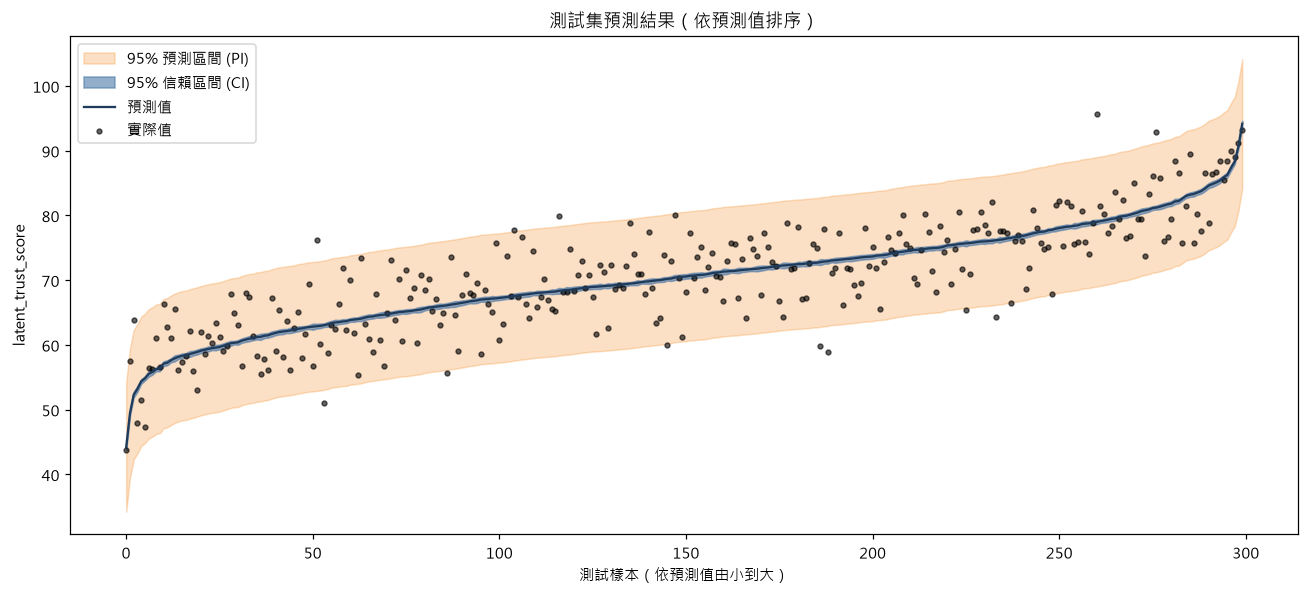

In [32]:
pred = ols.get_prediction(sm.add_constant(X_test[selected], has_constant="add")).summary_frame(alpha=0.05)
pred["actual"] = y_test.values
pred = pred.sort_values("mean").reset_index(drop=True)

in_pi = ((pred["actual"] >= pred["obs_ci_lower"]) & (pred["actual"] <= pred["obs_ci_upper"])).mean()
print(f"測試集實際值落在 95% 預測區間內的比例：{in_pi:.1%}（理想約 95%）")

sub = pred.iloc[np.linspace(0, len(pred) - 1, 300).astype(int)]  # 等距抽樣 300 點方便閱讀
x = np.arange(len(sub))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.fill_between(x, sub["obs_ci_lower"], sub["obs_ci_upper"], color="#F58518", alpha=0.25, label="95% 預測區間 (PI)")
ax.fill_between(x, sub["mean_ci_lower"], sub["mean_ci_upper"], color="#4C78A8", alpha=0.6, label="95% 信賴區間 (CI)")
ax.plot(x, sub["mean"], color="#1F3B5C", lw=1.5, label="預測值")
ax.scatter(x, sub["actual"], s=10, color="black", alpha=0.6, label="實際值")
ax.set(title="測試集預測結果（依預測值排序）", xlabel="測試樣本（依預測值由小到大）", ylabel=TARGET)
ax.legend(); plt.tight_layout(); plt.show()

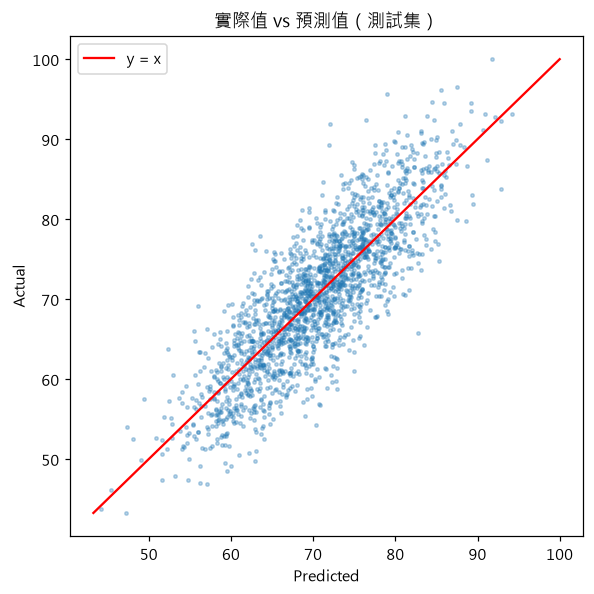

In [33]:
# 實際值 vs 預測值
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(pred["mean"], pred["actual"], s=5, alpha=0.3)
lim = [min(pred["mean"].min(), pred["actual"].min()), max(pred["mean"].max(), pred["actual"].max())]
ax.plot(lim, lim, color="red", label="y = x")
ax.set(title="實際值 vs 預測值（測試集）", xlabel="Predicted", ylabel="Actual"); ax.legend()
plt.tight_layout(); plt.show()

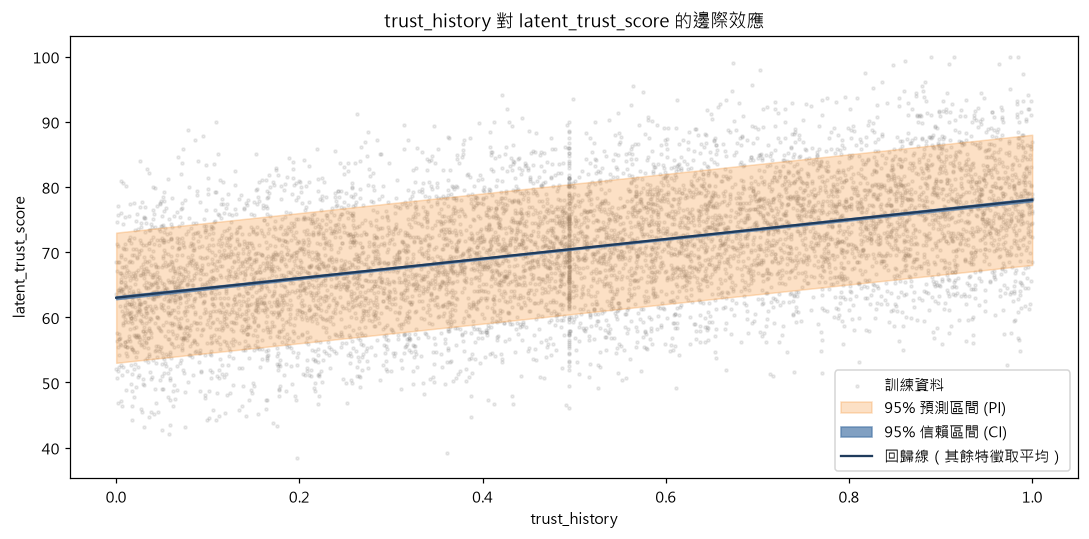

In [34]:
# 單一特徵的邊際效應：其餘特徵固定在訓練集平均，只變動 trust_history
focus = "trust_history"
grid = pd.DataFrame([X_train[selected].mean()] * 200)
grid[focus] = np.linspace(X_train[focus].min(), X_train[focus].max(), 200)
gp = ols.get_prediction(sm.add_constant(grid[selected], has_constant="add")).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_train[focus], y_train, s=4, alpha=0.15, color="gray", label="訓練資料")
ax.fill_between(grid[focus], gp["obs_ci_lower"], gp["obs_ci_upper"], color="#F58518", alpha=0.25, label="95% 預測區間 (PI)")
ax.fill_between(grid[focus], gp["mean_ci_lower"], gp["mean_ci_upper"], color="#4C78A8", alpha=0.7, label="95% 信賴區間 (CI)")
ax.plot(grid[focus], gp["mean"], color="#1F3B5C", label="回歸線（其餘特徵取平均）")
ax.set(title=f"{focus} 對 {TARGET} 的邊際效應", xlabel=focus, ylabel=TARGET)
ax.legend(); plt.tight_layout(); plt.show()

### 5.4 重要特徵與標準化係數

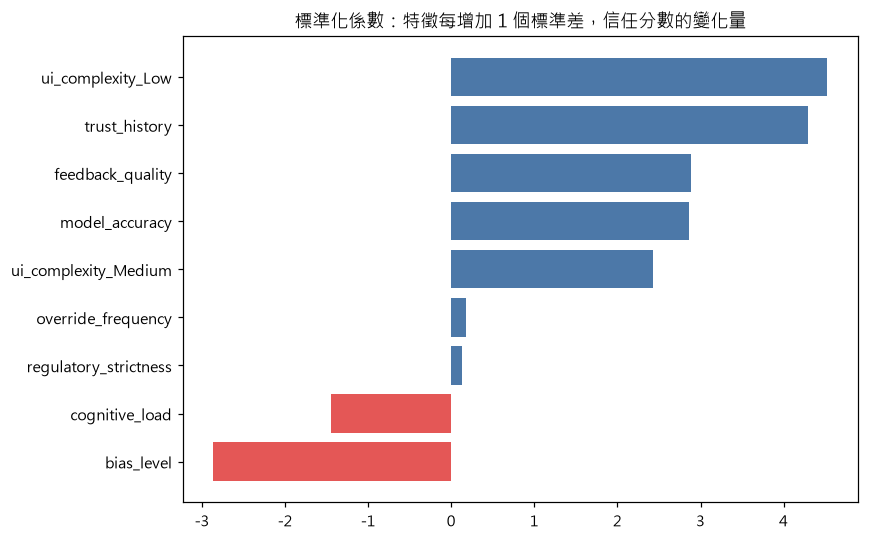

In [35]:
# 標準化係數（係數 × 特徵標準差），可比較各特徵影響力大小
std_coef = (ols.params.drop("const") * X_train[selected].std()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(std_coef.index, std_coef.values, color=["#E45756" if v < 0 else "#4C78A8" for v in std_coef.values])
ax.set(title="標準化係數：特徵每增加 1 個標準差，信任分數的變化量"); plt.tight_layout(); plt.show()

## 6. Deployment

將最終模型所需的資訊（係數、共變異數矩陣、殘差變異、插補值與編碼規則）存成 `models/model.joblib`，供 Streamlit App（`app.py`）載入。App 以此計算預測值，並用 `√(xᵀ·Cov·x + σ²)` 計算 95% 預測區間，無需在 App 內重新訓練。

執行方式：

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [36]:
# 記錄每個「被選中的欄位」對應的原始特徵，供 App 產生輸入元件
X_levels = {c: pd.concat([train_raw[c], test_raw[c]]).unique() for c in cat_cols}
dummy_map = {}
for c in cat_cols:
    for lvl in sorted(X_levels[c])[1:]:       # drop_first 之後保留的水準
        dummy_map[f"{c}_{lvl}"] = (c, lvl)

artifact = {
    "target": TARGET,
    "selected": selected,
    "params": ols.params,
    "cov": ols.cov_params(),
    "scale": float(ols.scale),
    "df_resid": float(ols.df_resid),
    "num_features": [c for c in selected if c in num_cols],
    "dummy_map": {k: v for k, v in dummy_map.items() if k in selected},
    "cat_levels": {c: sorted(X_levels[c]) for c in cat_cols},
    "num_range": {c: (float(data[c].min()), float(data[c].max()), float(num_median[c])) for c in num_cols},
    "metrics": results.loc["特徵選擇後 - Test"].to_dict(),
    "target_range": (float(data[TARGET].min()), float(data[TARGET].max())),
    "comparison": comparison,
    "selection": selection_rmse,
    "results": results,
    "test_pred": pred[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper", "actual"]],
    "split_sizes": (len(X_train), len(X_test)),
    "n_raw": (int(df.shape[0]), int(len(data))),
    "checks": checks,
    "resid": resid.values,
    "fitted": fitted.values,
    "resid_skew": float(stats.skew(resid)),
    "resid_kurt": float(stats.kurtosis(resid)),
}
joblib.dump(artifact, "models/model.joblib")
print("已儲存 models/model.joblib")

已儲存 models/model.joblib


## 7. 結論

### 模型表現
- 最終模型以 9 個特徵解釋約 **69%** 的信任分數變異（Test R² = 0.694、Adj R² = 0.693），Test RMSE ≈ **4.96**（目標變數標準差約 9.1，誤差約為原本的一半）。
- 與全特徵 30 個變數的模型相比，Test R² 完全相同（0.694）、5-fold CV RMSE 也幾乎一樣（5.098 vs 5.096），表示被剔除的 21 個變數沒有提供額外預測力，特徵選擇有效且未過度擬合（Train / Test 表現接近）。
- 測試集有 **95.5%** 的實際值落在 95% 預測區間內，與理論值 95% 吻合，表示區間校準良好。

### 影響信任分數的因素（其餘特徵固定時）
| 特徵 | 係數 | 解讀 |
|---|---|---|
| `trust_history`（0~1） | +15.0 | 影響最大：過去信任經驗越高，信任分數越高 |
| `model_accuracy`（0~1） | +20.0 | 模型越準，信任越高（已吸收 `error_rate` 的資訊） |
| `bias_level`（0~1） | −10.1 | AI 偏誤感知越高，信任越低 |
| `feedback_quality`（0~1） | +10.1 | 回饋品質越好，信任越高 |
| `cognitive_load`（0~1） | −5.1 | 認知負荷越重，信任越低 |
| `ui_complexity` | Low +9.9、Medium +4.9（相對 High） | 介面越簡單，信任越高 |
| `override_frequency`、`regulatory_strictness` | +0.03、+0.09 | 統計上顯著，但效果量極小，實務意義有限 |

年齡、教育程度、領域、文化背景、決策延遲、可解釋性分數等在控制其他變數後，沒有顯著影響。

### 限制與後續
- 資料多數特徵為 0~1 均勻分布，推測為模擬資料；真實場景的相關結構可能不同，結論不宜直接推論到真實使用者。
- 目標變數上限為 100（可能有截尾），且模型僅解釋約 69% 變異，其餘為未觀測因素或隨機噪音。
- 回歸係數代表**關聯性**而非因果。
- 可嘗試的改進：加入交互作用項（例如 `model_accuracy × explainability_score`）、非線性模型，或針對截尾目標使用 Tobit 模型。